# DAY5 과제 01 : 상관분석 기초문제

데이터 파일 : `auto_mpg.csv` (자동차 398대, 실습 04와 같은 파일)
출처 : UCI Machine Learning Repository - [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (CC BY 4.0)


- 유의수준은 α = 0.05, 양측으로 한다
- 결론은 두 줄로 쓴다 — 통계적 결론과 사실적 결론
- 이 과제에서는 자동차별 관측이 서로 독립이라고 가정한다

| 열 이름 | 뜻 | 단위 |
|---|---|---|
| `mpg` | 연비. 클수록 연료를 덜 쓴다 | 마일/갤런 |
| `cylinders` | 실린더(기통) 수 | 개 |
| `displacement` | 배기량 | 세제곱인치 |
| `horsepower` | 마력. 결측 6건 | 마력 |
| `weight` | 무게 | 파운드 |
| `acceleration` | 가속시간 : 시속 0 → 60마일에 걸리는 시간. 클수록 느린 차 | 초 |
| `origin` | 생산지역 (usa · europe · japan) | 없음 |

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "auto_mpg.csv")

df = pd.read_csv(csv_path)

data = df.copy()

## 1부. 산점도와 상관계수

### 1. 6기통 차(`cylinders` 가 6)만 골라 `six` 로 저장하고, 대수와 무게 · 가속시간의 결측 개수를 확인하시오.

In [ ]:
six = data[data["cylinders"] == 6]
print("6기통 차:", len(six), "대")
six[["weight", "acceleration"]].isna().sum()

6기통 차: 84 대


weight          0
acceleration    0
dtype: int64

### 2. 6기통 차의 무게(x)와 가속시간(y)으로 산점도를 그리고, 피어슨 상관계수를 구하시오. (소수 셋째 자리까지)

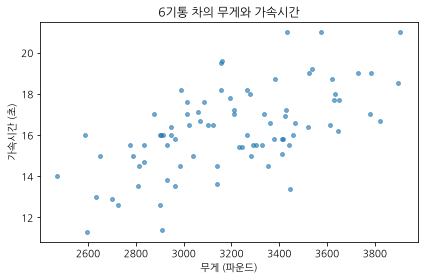

피어슨 r: 0.599


In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(six["weight"], six["acceleration"], s=15, alpha=0.6)
plt.xlabel("무게 (파운드)")
plt.ylabel("가속시간 (초)")
plt.title("6기통 차의 무게와 가속시간")
plt.tight_layout()
plt.show()

print("피어슨 r:", round(six["weight"].corr(six["acceleration"]), 3))

### 3. 6기통 차의 무게 · 가속시간 공분산을 구하시오. 그다음 무게를 킬로그램으로 바꿔(1파운드 = 0.4536kg) 공분산과 피어슨 상관계수를 다시 구하시오. (공분산은 소수 둘째 자리, 상관계수는 소수 셋째 자리까지)

In [ ]:
print("공분산 (파운드 × 초):", round(six["weight"].cov(six["acceleration"]), 2))

weight_kg = six["weight"] * 0.4536                       # 파운드 → 킬로그램
print("공분산 (킬로그램 × 초):", round(weight_kg.cov(six["acceleration"]), 2))
print("상관계수 (파운드):", round(six["weight"].corr(six["acceleration"]), 3))
print("상관계수 (킬로그램):", round(weight_kg.corr(six["acceleration"]), 3))

공분산 (파운드 × 초): 402.25
공분산 (킬로그램 × 초): 182.46
상관계수 (파운드): 0.599
상관계수 (킬로그램): 0.599


### 4. 전체 자동차의 배기량(x)과 연비(y)로 산점도를 그리고, 피어슨 · 스피어만 상관계수를 둘 다 구하시오. (소수 셋째 자리까지)

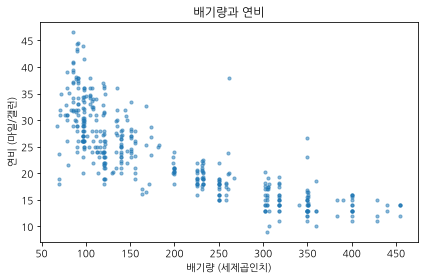

피어슨 r: -0.804
스피어만 ρs: -0.856


In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(data["displacement"], data["mpg"], s=10, alpha=0.5)
plt.xlabel("배기량 (세제곱인치)")
plt.ylabel("연비 (마일/갤런)")
plt.title("배기량과 연비")
plt.tight_layout()
plt.show()

print("피어슨 r:", round(data["displacement"].corr(data["mpg"]), 3))
print("스피어만 ρs:", round(data["displacement"].corr(data["mpg"], method="spearman"), 3))

## 2부. 상관행렬과 히트맵

### 5. `mpg`, `displacement`, `horsepower`, `weight`, `acceleration` 다섯 변수의 피어슨 상관행렬을 구하고(소수 셋째 자리까지), 색 범위를 −1 ~ 1로 고정한 히트맵을 그리시오.

,mpg,displacement,horsepower,weight,acceleration
mpg,1.000,-0.804,-0.778,-0.832,0.420
displacement,-0.804,1.000,0.897,0.933,-0.544
horsepower,-0.778,0.897,1.000,0.865,-0.689
weight,-0.832,0.933,0.865,1.000,-0.417
acceleration,0.420,-0.544,-0.689,-0.417,1.000


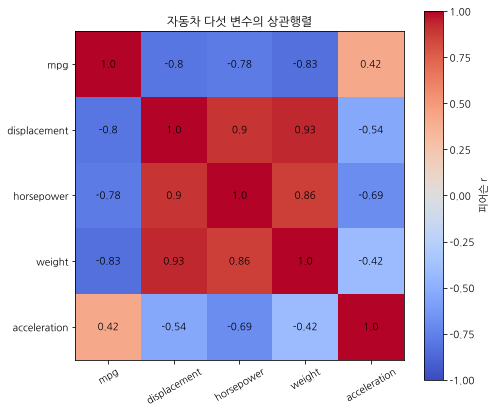

In [ ]:
car_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
car_matrix = data[car_cols].corr()          # 결측이 있는 horsepower 는 쌍마다 두 값이 모두 있는 행으로 계산한다
display(car_matrix.round(3))

plt.figure(figsize=(7, 6))
image = plt.imshow(car_matrix, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(image, label="피어슨 r")
plt.xticks(range(5), car_cols, rotation=30)
plt.yticks(range(5), car_cols)
for i in range(5):
    for j in range(5):
        plt.text(j, i, round(car_matrix.iloc[i, j], 2), ha="center", va="center")
plt.title("자동차 다섯 변수의 상관행렬")
plt.tight_layout()
plt.show()

## 3부. 층화 분석

### 6. 미국 차(`origin` 이 usa)만 골라 무게 · 가속시간의 피어슨 상관계수를 구하시오. 그다음 기통 수(`cylinders`)별로 나눠 대수와 피어슨 상관계수를 다시 구하시오. (소수 셋째 자리까지)

In [ ]:
usa = data[data["origin"] == "usa"]
print("미국 차 전체:", len(usa), "대 / r:", round(usa["weight"].corr(usa["acceleration"]), 3))

display(usa.groupby("cylinders").size())                                        # 기통 수별 대수
display(usa.groupby("cylinders")[["weight", "acceleration"]].corr().round(3))   # 기통 수별 2 × 2 상관표

미국 차 전체: 249 대 / r: -0.445


cylinders
4     72
6     74
8    103
dtype: int64

weight  acceleration
cylinders                                   
4         weight         1.000         0.110
          acceleration   0.110         1.000
6         weight         1.000         0.603
          acceleration   0.603         1.000
8         weight         1.000         0.017
          acceleration   0.017         1.000

## 4부. 상관계수 검정

검정 문제는 실습 04의 다섯 단계를 따른다. **목적 · 자료 확인 → 산점도와 방법 우선 선택 → 조건 확인 및 재검토 → 최종 가설 · 검정 → 보고**

### 7. 6기통 차의 무게와 가속시간이 직선처럼 함께 움직이는지 검정하려 한다. 2번 산점도로 방법을 우선 고른 뒤, 두 변수의 Shapiro-Wilk 정규성 검정 p값을 각각 구하시오. (소수 셋째 자리까지)

- 귀무가설(H₀): 이 변수는 정규분포를 따른다.
- 대립가설(H₁): 이 변수는 정규분포를 따르지 않는다.

In [ ]:
# 2번 산점도 : 오른쪽 위로 올라가는 직선 띠, 휜 곡선 아님 → 피어슨을 우선 고른다
print("무게 shapiro p값:", round(stats.shapiro(six["weight"]).pvalue, 3))
print("가속시간 shapiro p값:", round(stats.shapiro(six["acceleration"]).pvalue, 3))

무게 shapiro p값: 0.602
가속시간 shapiro p값: 0.59


### 8. 7번 결과로 최종 방법을 정하고, 6기통 차의 무게와 가속시간의 상관계수 · p값 · 95% 신뢰구간을 구하시오.

- 귀무가설(H₀): 모집단에서 6기통 차의 무게와 가속시간은 상관이 없다. (ρ = 0)
- 대립가설(H₁): 모집단에서 6기통 차의 무게와 가속시간은 상관이 있다. (ρ ≠ 0)

In [ ]:
six_result = stats.pearsonr(six["weight"], six["acceleration"])
six_ci = six_result.confidence_interval(confidence_level=0.95)
print("n:", len(six))
print("r:", round(six_result.statistic, 3))
print("p값:", six_result.pvalue)
print("95% 신뢰구간:", round(six_ci.low, 3), "~", round(six_ci.high, 3))

n: 84
r: 0.599
p값: 1.7657630159837928e-09
95% 신뢰구간: 0.441 ~ 0.721


### 9. 전체 자동차의 배기량과 연비는 4번 산점도에서 한 방향으로 휜 곡선이었다. 알맞은 방법으로 상관계수와 p값을 구하시오.

- 귀무가설(H₀): 모집단에서 자동차의 배기량과 연비는 상관이 없다. (ρs = 0)
- 대립가설(H₁): 모집단에서 자동차의 배기량과 연비는 상관이 있다. (ρs ≠ 0)

In [ ]:
disp_result = stats.spearmanr(data["displacement"], data["mpg"])
print("n:", len(data))
print("ρs:", round(disp_result.statistic, 3))
print("p값:", disp_result.pvalue)

n: 398
ρs: -0.856
p값: 2.364635377968719e-115


## 확인문제

앞의 결과를 보고 답을 1~2문장으로 적으시오.

### 확인 1. 3번에서 무게를 킬로그램으로 바꾸자 공분산은 어떻게 되었고, 상관계수는 어떻게 되었는가?

**답 :** 공분산은 402.25에서 182.46으로 0.4536배가 되었고, 상관계수는 0.599로 그대로다.

### 확인 2. 4번 결과로 볼 때, 배기량과 연비의 관계를 요약할 때 피어슨과 스피어만 중 무엇이 알맞은가? 이유도 쓰시오.

**답 :** 스피어만이 알맞다. 산점도가 오른쪽 아래로 내려가는 한 방향의 휜 곡선이라 직선 관계를 보는 피어슨(−0.804)보다 순위로 계산하는 스피어만(−0.856)이 관계를 더 잘 요약한다.

### 확인 3. 7번 결과를 보고, 8번에서 피어슨을 그대로 쓴 이유를 쓰시오.

**답 :** 산점도가 직선 띠이고, Shapiro p값이 무게 0.602, 가속시간 0.590으로 둘 다 0.05 이상이라 정규성에 큰 문제가 없다. 그래서 우선 고른 피어슨을 최종 방법으로 쓴다.

### 확인 4. 8번의 통계적 결론과 사실적 결론을 쓰시오.

**답 :** 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다.<br>사실적 결론 : 모집단에서 6기통 차의 무게와 가속시간은 상관이 있다고 볼 통계적 근거가 있다. 무거운 6기통 차일수록 가속시간이 긴 보통 정도의 양의 상관이 관찰되었다 (r = 0.599, 95% 신뢰구간 0.441 ~ 0.721, n = 84).

### 확인 5. 9번의 통계적 결론과 사실적 결론을 쓰시오.

**답 :** 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다.<br>사실적 결론 : 모집단에서 자동차의 배기량과 연비는 상관이 있다고 볼 통계적 근거가 있다. 배기량이 큰 차일수록 연비가 낮은 강한 음의 상관이 관찰되었다 (ρs = −0.856, n = 398).

### 확인 6. 8번 결과로 "무게가 무거워서 6기통 차의 가속이 느려진다"고 말할 수 있는가?

**답 :** 말할 수 없다. 상관검정은 두 변수가 함께 움직인다는 것까지만 보여 준다. 관찰자료라서 무게가 원인인지는 이 결과만으로 알 수 없다.

## 개념 확인 (객관식)

알맞은 답의 번호를 하나 고르시오.

### 개념 1. 피어슨 상관계수 r이 가질 수 있는 값의 범위는?

① 0 ~ 1  
② −1 ~ 1  
③ 0 ~ 100  
④ 제한이 없다

**답 :** ② — 상관계수는 −1 ~ 1 사이다. 부호는 방향, 절댓값은 강도를 나타낸다.

### 개념 2. 두 변수의 상관계수가 r = −0.85 였다. 알맞은 해석은?

① 관계가 거의 없다  
② 강한 양의 상관이다  
③ 강한 음의 상관이다  
④ 한 변수가 다른 변수의 원인이다

**답 :** ③ — 절댓값이 0.7 이상이면 강하다고 읽고, 부호가 음수이므로 한쪽이 커질 때 다른 쪽은 작아지는 관계다.

### 개념 3. 공분산 대신 상관계수로 관계의 강도를 비교하는 이유는?

① 공분산은 항상 양수라서  
② 공분산은 단위에 따라 크기가 바뀌어서  
③ 공분산은 계산할 수 없어서  
④ 공분산은 방향을 알려 주지 않아서

**답 :** ② — 공분산은 두 변수 단위의 곱이라 단위를 바꾸면 크기가 달라진다. 상관계수는 단위가 없어 비교할 수 있다.

### 개념 4. 산점도가 한 방향으로 계속 내려가는 휜 곡선이다. 관계를 요약하기에 알맞은 계수는?

① 피어슨 상관계수  
② 스피어만 상관계수  
③ 공분산  
④ 표준편차

**답 :** ② — 스피어만은 순위로 계산하므로 직선이 아니어도 한 방향으로 변하는 관계(단조 관계)를 잘 요약한다.

### 개념 5. 두 수치형 변수의 산점도가 직선이고, 두 변수 모두 정규성 검정에서 기각되지 않았다. 알맞은 검정은?

① `stats.pearsonr`  
② `stats.spearmanr`  
③ `stats.chisquare`  
④ `stats.f_oneway`

**답 :** ① — 직선 관계이고 정규성에 큰 문제가 없으므로 피어슨 상관계수 검정을 쓴다.

### 개념 6. 상관행렬에서 절댓값이 큰 쌍을 찾았다. 그다음 할 일로 알맞은 것은?

① 바로 원인이라고 결론 낸다  
② 그 쌍의 산점도를 그려 관계의 모양 · 이상값 · 군집을 확인한다  
③ 나머지 쌍은 모두 지운다  
④ 대각선 값을 확인한다

**답 :** ② — 상관행렬은 볼 곳을 고르는 도구다. 관계의 모양과 이상값은 산점도로 확인한다.

### 개념 7. 상관행렬에서 대각선 칸의 값은 항상 얼마인가?

① 0  
② 0.5  
③ 1  
④ −1

**답 :** ③ — 대각선은 변수 자기 자신과의 상관이라 항상 1이다.

### 개념 8. 미국 차 전체에서는 무게와 가속시간의 상관이 r = −0.45 였는데, 기통 수별로 나누자 0.11, 0.60, 0.02 로 달라졌다. 알맞은 해석은?

① 계산이 잘못되었다  
② 성격이 다른 집단(기통 수)이 섞여 있어 전체 상관이 집단 안의 관계와 다르게 나왔다  
③ 전체 상관만 믿으면 된다  
④ 집단으로 나누면 상관계수는 항상 커진다

**답 :** ② — 성격이 다른 집단이 섞이면 전체 관계가 집단 안의 관계를 가리거나 뒤집을 수 있다. 의미 있는 기준으로 나눠 다시 보는 것이 층화 분석이다.

### 개념 9. 상관계수 검정 결과 p = 0.30 이었다 (α = 0.05). 알맞은 결론은?

① 모집단에서 두 변수는 상관이 없다는 것이 증명되었다  
② 귀무가설을 기각하지 못한다. 상관이 있다고 볼 근거가 부족하다  
③ 귀무가설을 기각한다  
④ 강한 상관이 있다

**답 :** ② — 기각하지 못했다고 '상관이 없다'가 증명된 것은 아니다. '상관이 있다고 볼 근거가 부족하다'로 쓴다.

### 개념 10. 아이스크림 판매량과 물놀이 사고 건수의 상관이 유의하게 나왔다. 알맞은 해석은?

① 아이스크림이 사고의 원인이다  
② 두 변수가 함께 움직이는 관계까지만 말할 수 있다  
③ 사고가 아이스크림 판매의 원인이다  
④ p값이 작으므로 인과관계가 증명되었다

**답 :** ② — 상관은 인과가 아니다. 더운 날씨처럼 두 변수를 함께 움직이는 다른 요인이 있을 수 있다.